# Polynomial Regression

Fits curves with a linear model by expanding the inputs: for one feature `x` and degree 3 the model sees `[x, x², x³]` and learns a weight for each. It is still **linear in the weights**, so the least-squares solution from `01_linear_regression` applies unchanged — only the features change.

With several features, cross terms are included (`a·b`, `a²·b`, ...), so the feature count grows fast with degree.

Higher degree fits training data better but overfits; pair with Ridge (`02_ridge_lasso`) for high degrees. Scale features first for degree > 3 or wide-range data.

## Usage

```python
# (the class is defined in the Implementation section below)

model = PolynomialRegression(degree=3).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
from itertools import combinations_with_replacement

import numpy as np


def polynomial_features(X, degree):
    """All monomials of the features up to `degree` (no constant column).
    For features a, b and degree 2: a, b, a^2, a*b, b^2."""
    X = np.asarray(X, dtype=float)
    cols = [
        np.prod(X[:, combo], axis=1)
        for d in range(1, degree + 1)
        for combo in combinations_with_replacement(range(X.shape[1]), d)
    ]
    return np.column_stack(cols)


class PolynomialRegression:
    """Linear regression on polynomial features: still linear in the weights, curved in x.

    ponytail: no feature scaling, high degrees on wide-range data get ill-conditioned.
    Standardize X first or add a ridge penalty if that bites."""

    def __init__(self, degree=2):
        self.degree = degree
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        P = polynomial_features(X, self.degree)
        A = np.hstack([np.ones((len(P), 1)), P])
        theta, *_ = np.linalg.lstsq(A, np.asarray(y, dtype=float), rcond=None)
        self.bias, self.weights = theta[0], theta[1:]
        return self

    def predict(self, X):
        return polynomial_features(X, self.degree) @ self.weights + self.bias

## See it work

### 1. Underfit, good fit, overfit

Noisy samples of a sine wave. Degree 1 is too stiff (underfits), degree 3-5 captures the shape, degree 15 chases the noise and swings wildly between points (overfits). It is still *linear regression*, just on the features `x, x², x³, …`.

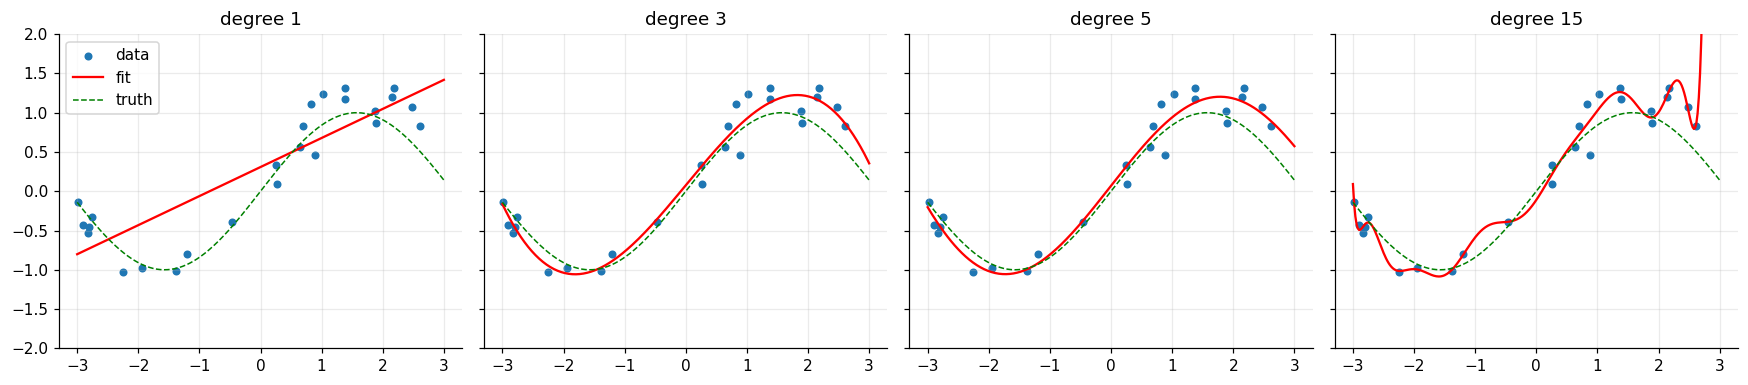

In [3]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(-3, 3, 25))
y = np.sin(x) + rng.normal(scale=0.25, size=25)
xs = np.linspace(-3, 3, 300)[:, None]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, d in zip(axes, [1, 3, 5, 15]):
    m = PolynomialRegression(degree=d).fit(x[:, None], y)
    ax.scatter(x, y, s=18, label="data"); ax.plot(xs, m.predict(xs), "r", label="fit"); ax.plot(xs, np.sin(xs), "g--", lw=1, label="truth")
    ax.set(title=f"degree {d}", ylim=(-2, 2))
axes[0].legend()
plt.tight_layout(); plt.show()

### 2. Choosing the degree: train vs validation error

Training error keeps falling with degree. Validation error falls, then **rises** once the model starts fitting noise. Pick the degree where validation error is lowest.

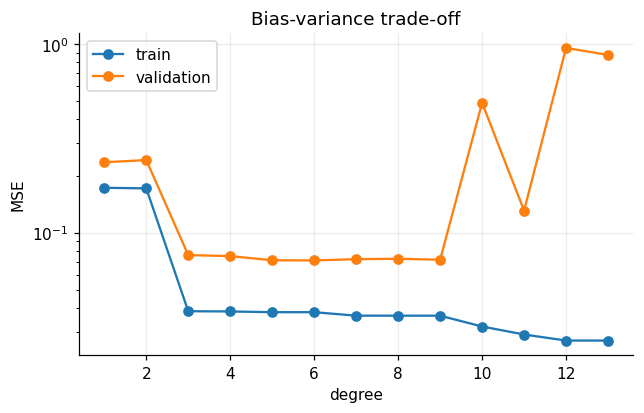

In [4]:
x_all = rng.uniform(-3, 3, 400); y_all = np.sin(x_all) + rng.normal(scale=0.25, size=400)
xtr, ytr, xva, yva = x_all[:30], y_all[:30], x_all[30:], y_all[30:]
degrees = range(1, 14)
tr, va = [], []
for d in degrees:
    m = PolynomialRegression(degree=d).fit(xtr[:, None], ytr)
    tr.append(np.mean((m.predict(xtr[:, None]) - ytr) ** 2)); va.append(np.mean((m.predict(xva[:, None]) - yva) ** 2))
plt.figure(figsize=(6.5, 3.8))
plt.semilogy(list(degrees), tr, "o-", label="train"); plt.semilogy(list(degrees), va, "o-", label="validation")
plt.xlabel("degree"); plt.ylabel("MSE"); plt.title("Bias-variance trade-off"); plt.legend(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(42)
X = rng.uniform(-3, 3, size=(150, 2))
y = 1 + 2 * X[:, 0] - X[:, 1] + 0.5 * X[:, 0] ** 2 + X[:, 0] * X[:, 1] + rng.normal(scale=0.3, size=150)

for degree in (1, 2, 3):
    ours = PolynomialRegression(degree=degree).fit(X, y)
    theirs = make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression()).fit(X, y)
    mse = np.mean((ours.predict(X) - y) ** 2)
    print("degree %d: train MSE=%.4f" % (degree, mse))
    assert np.allclose(ours.predict(X), theirs.predict(X), atol=1e-6)

degree 1: train MSE=11.5197
degree 2: train MSE=0.0902
degree 3: train MSE=0.0891


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def test_feature_expansion():
    X = np.array([[2.0, 3.0]])
    # a, b, a^2, a*b, b^2
    assert polynomial_features(X, 2).tolist() == [[2.0, 3.0, 4.0, 6.0, 9.0]]
    assert polynomial_features(X, 1).tolist() == [[2.0, 3.0]]


def test_recovers_exact_cubic():
    rng = np.random.default_rng(0)
    X = rng.uniform(-2, 2, size=(100, 1))
    y = 2 * X[:, 0] ** 3 - X[:, 0] ** 2 + 0.5 * X[:, 0] + 4
    model = PolynomialRegression(degree=3).fit(X, y)
    assert np.allclose(model.weights, [0.5, -1.0, 2.0], atol=1e-8)
    assert abs(model.bias - 4.0) < 1e-8


def test_higher_degree_fits_curve_better_than_a_line():
    rng = np.random.default_rng(1)
    X = rng.uniform(-3, 3, size=(200, 1))
    y = X[:, 0] ** 2 + rng.normal(scale=0.1, size=200)
    mse = lambda m: np.mean((m.predict(X) - y) ** 2)
    assert mse(PolynomialRegression(degree=2).fit(X, y)) < 0.05 * mse(PolynomialRegression(degree=1).fit(X, y))

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_feature_expansion
PASS test_recovers_exact_cubic
PASS test_higher_degree_fits_curve_better_than_a_line

all 3 tests passed


## Takeaways

- **Use it when** the relationship is smooth but curved and you have one or a few features. It is the simplest way to turn a linear model into a non-linear one: engineer features, keep the solver.
- **Pitfalls:** the number of features explodes (`d` features at degree `p` gives `C(d+p, p) − 1` terms), high degrees are numerically ill-conditioned (standardise `x` first or add a ridge penalty, `02_ridge_lasso`), and polynomials extrapolate terribly outside the training range (compare the wild tails above).
- **Interview line:** *"It is linear regression on `[x, x², …, xᵖ]`; the degree is the complexity knob, chosen on validation error."*